# Predicting Airfoil Self-Noise Using Deep Neural Networks

## 1. Project Overview

This project investigates the use of a feed-forward neural network to predict airfoil self-noise from aerodynamic measurements.

The problem is formulated as a supervised learning regression task. The model receives five measured aerodynamic characteristics as inputs and predicts the corresponding scaled sound pressure level in decibels (dB).

The project will be developed progressively, beginning with data exploration and preprocessing before moving into neural-network modelling.

The main concepts examined include:

- Neural-network architecture
- Activation functions
- Forward propagation
- Loss functions
- Backpropagation
- Optimizers
- Learning rate
- Learning curves
- Model comparison and selection

The objective is not simply to obtain a prediction model, but to understand how different neural-network design choices affect its performance on the airfoil self-noise problem.

In [5]:
import sys

print(sys.executable)

c:\Users\Tammy\anaconda3\python.exe


In [6]:
import numpy as np
import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 1.26.4
TensorFlow: 2.21.0


In [7]:
import sys

sys.path.append("../src")

from loader import load_airfoil_data
from preprocessing import DataPreprocessor
from visualization import (
    plot_feature_distributions,
    plot_target_distribution
)
from models import build_baseline_model
from evaluation import (
    calculate_regression_metrics,
    print_regression_metrics
)

In [8]:
df = load_airfoil_data("../data/raw/airfoil_self_noise.dat")

print(df.shape)
df.head()

(1503, 6)


,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_ms,suction_side_displacement_thickness_m,scaled_sound_pressure_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [9]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   frequency_hz                           1503 non-null   int64  
 1   angle_of_attack_deg                    1503 non-null   float64
 2   chord_length_m                         1503 non-null   float64
 3   free_stream_velocity_ms                1503 non-null   float64
 4   suction_side_displacement_thickness_m  1503 non-null   float64
 5   scaled_sound_pressure_db               1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB
None

Missing values:
frequency_hz                             0
angle_of_attack_deg                      0
chord_length_m                           0
free_stream_velocity_ms                  0
suction_side_displacement_thickness_m    0
scaled_sound_pressure_db                 0
dtype: int64


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
frequency_hz,1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,20000.000000
angle_of_attack_deg,1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,22.200000
chord_length_m,1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,0.304800
free_stream_velocity_ms,1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,71.300000
suction_side_displacement_thickness_m,1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,0.058411
scaled_sound_pressure_db,1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,140.987000


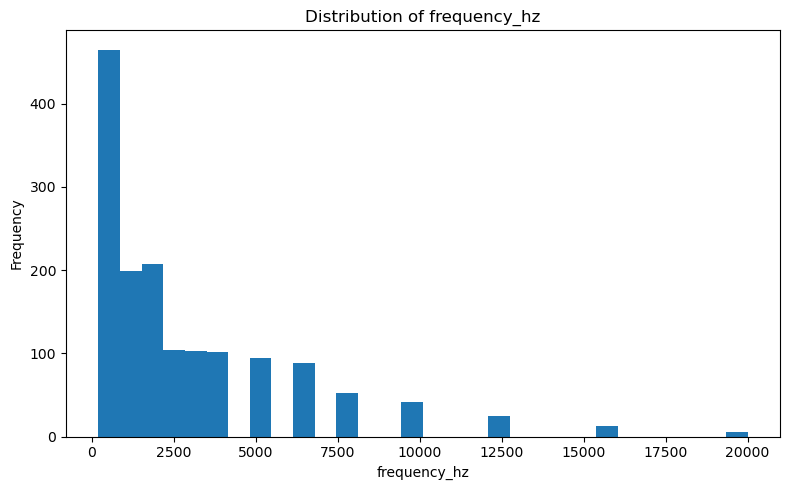

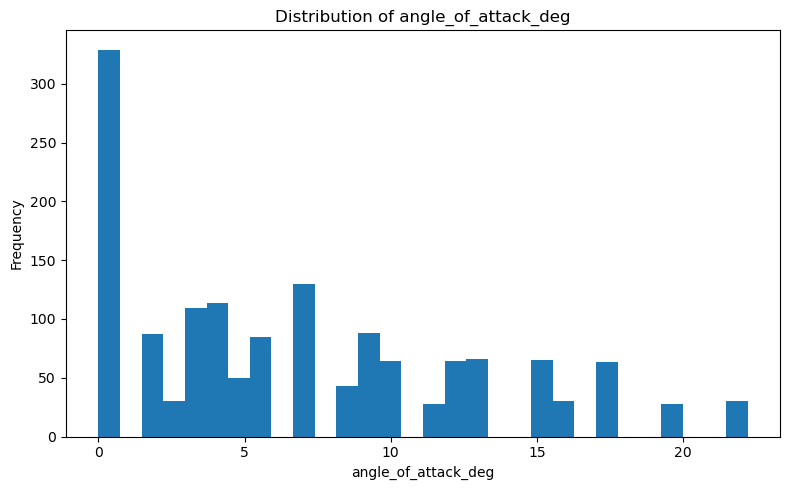

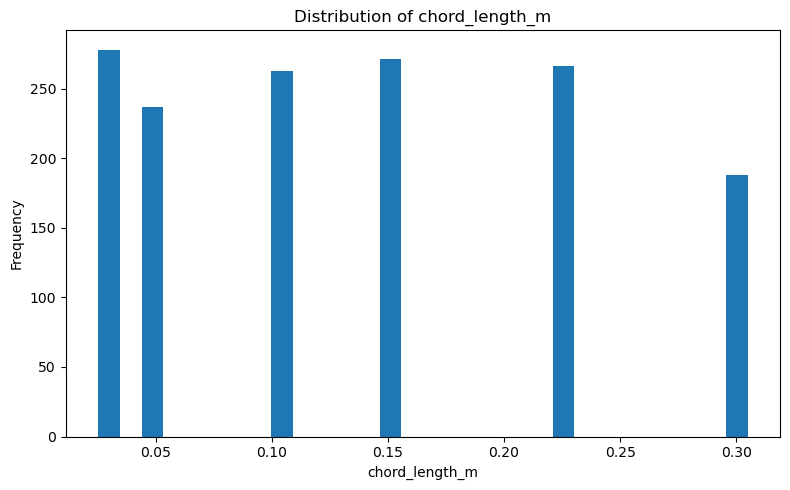

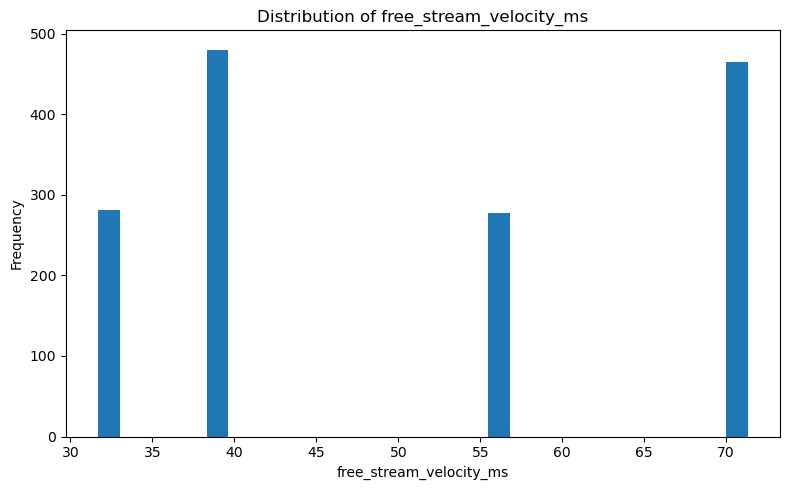

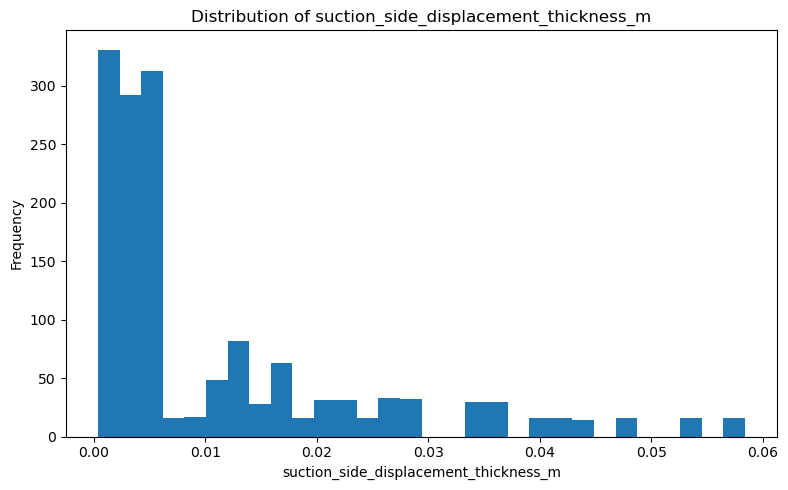

In [11]:
plot_feature_distributions(df, FEATURE_COLUMNS)

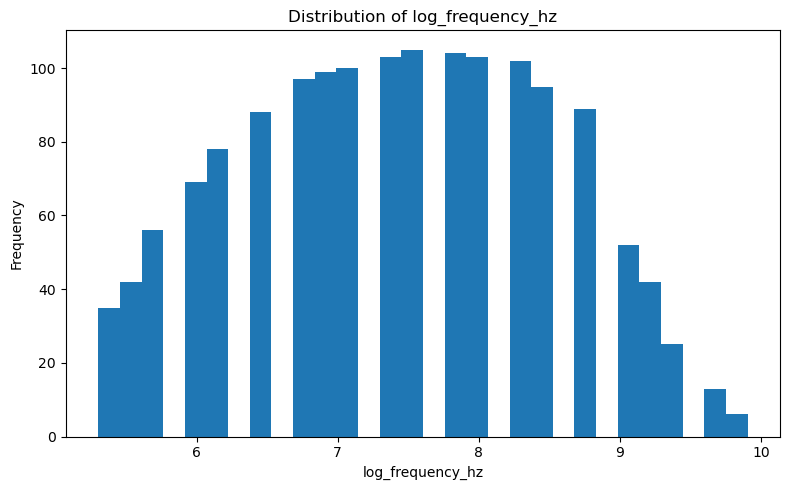

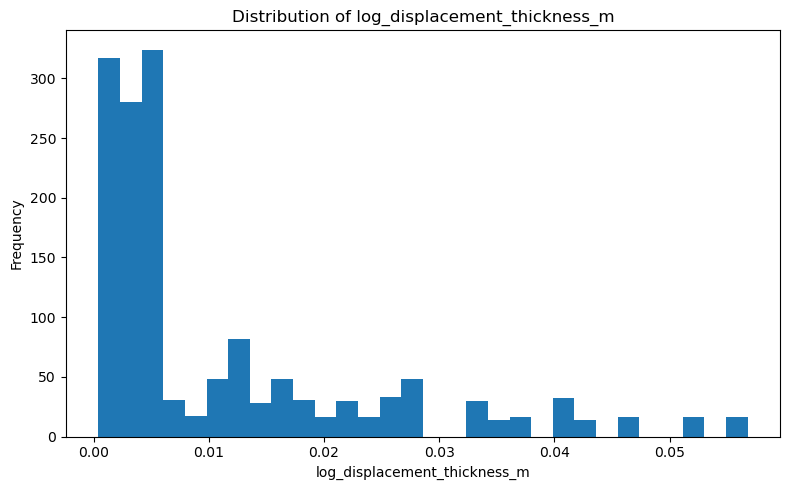

In [12]:
import numpy as np

df["log_frequency_hz"] = np.log1p(df["frequency_hz"])
df["log_displacement_thickness_m"] = np.log1p(
    df["suction_side_displacement_thickness_m"]
)

plot_feature_distributions(
    df,
    ["log_frequency_hz", "log_displacement_thickness_m"]
)

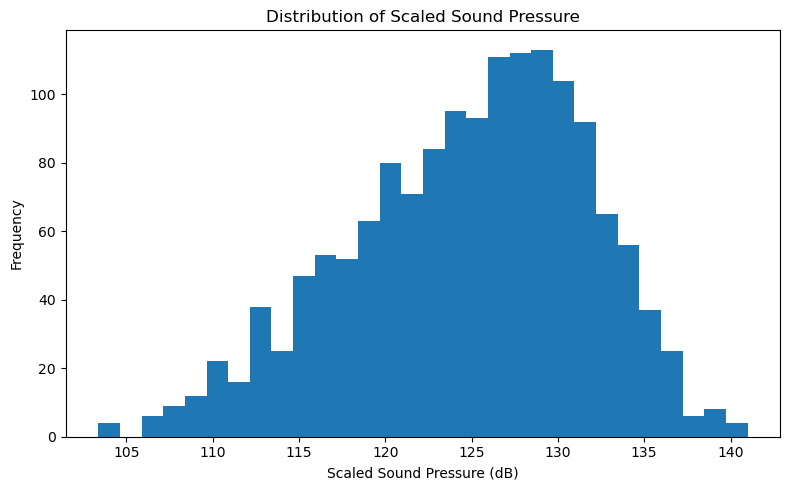

In [13]:
plot_target_distribution(df, TARGET_COLUMN)

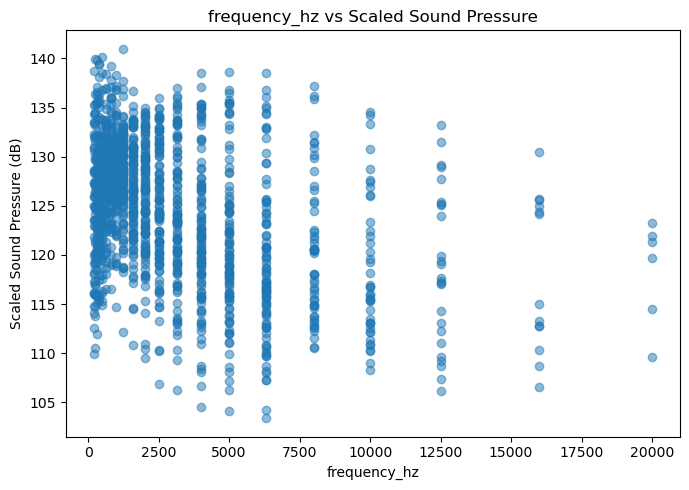

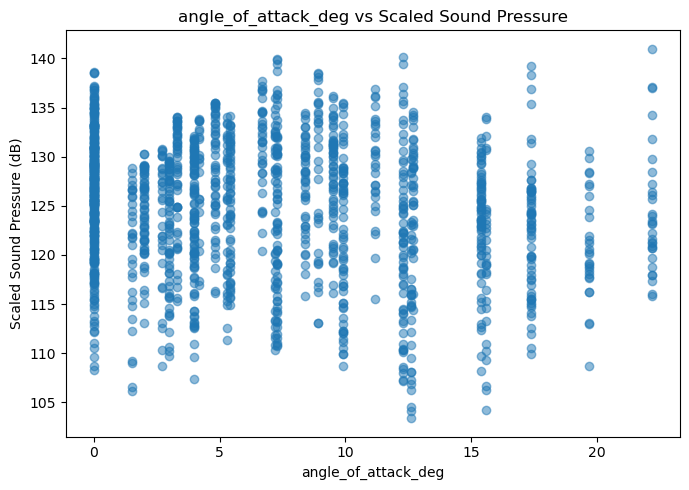

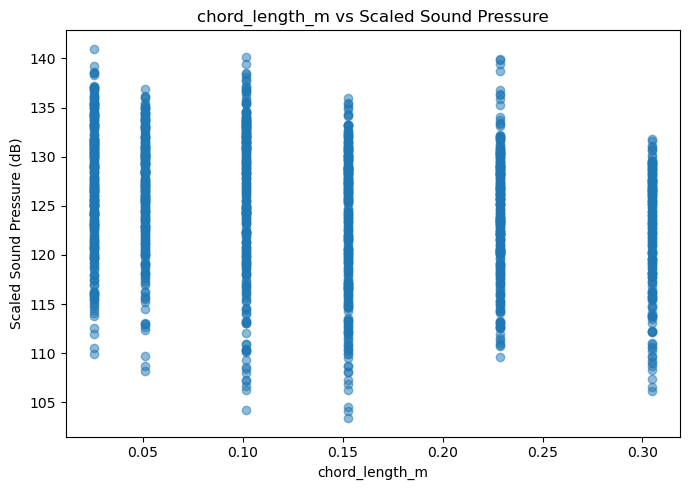

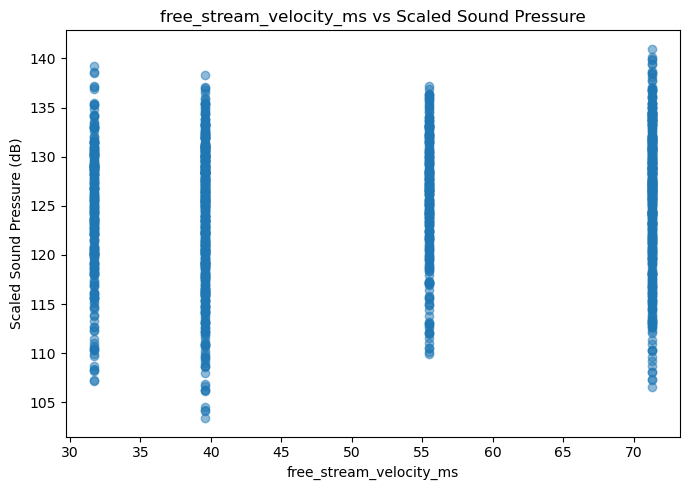

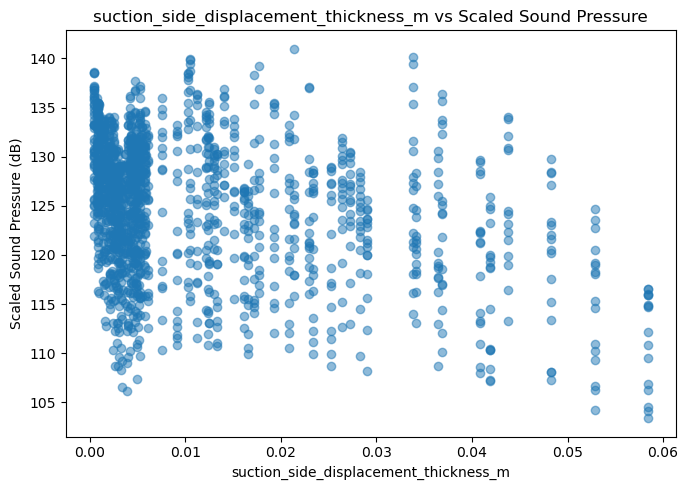

In [14]:
import matplotlib.pyplot as plt

for column in FEATURE_COLUMNS:
    plt.figure(figsize=(7, 5))
    plt.scatter(df[column], df[TARGET_COLUMN], alpha=0.5)
    plt.title(f"{column} vs Scaled Sound Pressure")
    plt.xlabel(column)
    plt.ylabel("Scaled Sound Pressure (dB)")
    plt.tight_layout()
    plt.show()

In [15]:
correlation_matrix = df[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()

correlation_matrix

,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_ms,suction_side_displacement_thickness_m,scaled_sound_pressure_db
frequency_hz,1.000000,-0.272765,-0.003661,0.133664,-0.230107,-0.390711
angle_of_attack_deg,-0.272765,1.000000,-0.504868,0.058760,0.753394,-0.156108
chord_length_m,-0.003661,-0.504868,1.000000,0.003787,-0.220842,-0.236162
free_stream_velocity_ms,0.133664,0.058760,0.003787,1.000000,-0.003974,0.125103
suction_side_displacement_thickness_m,-0.230107,0.753394,-0.220842,-0.003974,1.000000,-0.312670
scaled_sound_pressure_db,-0.390711,-0.156108,-0.236162,0.125103,-0.312670,1.000000


### DATA PREPROCESSING

In [16]:
from preprocessing import DataPreprocessor

preprocessor = DataPreprocessor(
    test_size=0.2,
    random_state=42
)

X, y = preprocessor.split_features_target(df)

X_train, X_test, y_train, y_test = preprocessor.split_data(X, y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1202, 5)
Testing features: (301, 5)
Training target: (1202,)
Testing target: (301,)


In [17]:
X_train_scaled, X_test_scaled = preprocessor.scale_features(
    X_train,
    X_test
)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nTraining means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining standard deviations:")
print(X_train_scaled.std(axis=0))

Scaled training shape: (1202, 5)
Scaled testing shape: (301, 5)

Training means:
[5.91133724e-18 3.54680234e-17 2.86699856e-16 3.04988056e-16
 4.43350293e-18]

Training standard deviations:
[1. 1. 1. 1. 1.]


In [18]:
model = build_baseline_model(X_train_scaled.shape[1])

model.summary()

c:\Users\Tammy\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 15433.2686 - mae: 124.0269 - val_loss: 15295.5430 - val_mae: 123.4789
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15104.6484 - mae: 122.6872 - val_loss: 14866.5840 - val_mae: 121.7157
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 14557.0850 - mae: 120.4216 - val_loss: 14156.7285 - val_mae: 118.7385
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 13691.4639 - mae: 116.7400 - val_loss: 13082.3457 - val_mae: 114.0741
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 12419.0635 - mae: 111.0920 - val_loss: 11576.7070 - val_mae: 107.1724
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 10707.9219 - mae: 102.9790 - val_loss: 9652.2197 - val_mae: 97.5867
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8645.2031 - mae: 92.1431 - val_loss: 7474.3701 - val_mae: 85.3681
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 6429.8730 - mae: 78.8015 - val_loss: 5288

In [20]:
y_pred = model.predict(X_test_scaled)

test_metrics = calculate_regression_metrics(
    y_test,
    y_pred.flatten()
)

print_regression_metrics(test_metrics)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
MAE:  4.1206
RMSE: 5.2105
R²:   0.4581


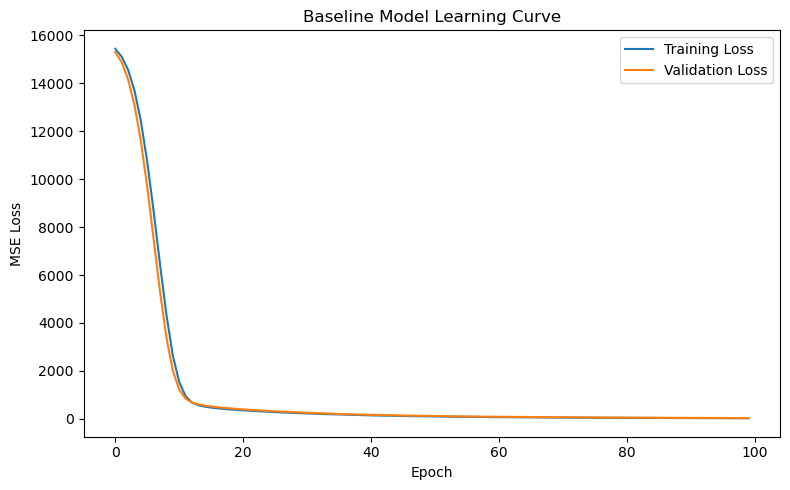

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Baseline Model Learning Curve")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
import numpy as np

df_log_freq = df.copy()

df_log_freq["frequency_hz"] = np.log1p(
    df_log_freq["frequency_hz"]
)

df_log_freq.head()

,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_ms,suction_side_displacement_thickness_m,scaled_sound_pressure_db,log_frequency_hz,log_displacement_thickness_m
0,6.685861,0.0,0.3048,71.3,0.002663,126.201,6.685861,0.00266
1,6.908755,0.0,0.3048,71.3,0.002663,125.201,6.908755,0.00266
2,7.131699,0.0,0.3048,71.3,0.002663,125.951,7.131699,0.00266
3,7.378384,0.0,0.3048,71.3,0.002663,127.591,7.378384,0.00266
4,7.601402,0.0,0.3048,71.3,0.002663,127.461,7.601402,0.00266


In [23]:
preprocessor_v1 = DataPreprocessor()

X_v1, y_v1 = preprocessor_v1.split_features_target(df_log_freq)

X_train_v1, X_test_v1, y_train_v1, y_test_v1 = (
    preprocessor_v1.split_data(X_v1, y_v1)
)

X_train_v1_scaled, X_test_v1_scaled = (
    preprocessor_v1.scale_features(
        X_train_v1,
        X_test_v1
    )
)

print("Training features:", X_train_v1_scaled.shape)
print("Testing features:", X_test_v1_scaled.shape)

Training features: (1202, 5)
Testing features: (301, 5)


In [24]:
model_v1 = build_baseline_model(
    X_train_v1_scaled.shape[1]
)

model_v1.summary()

c:\Users\Tammy\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history_v1 = model_v1.fit(
    X_train_v1_scaled,
    y_train_v1,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 15721.9990 - mae: 125.2010 - val_loss: 15667.3467 - val_mae: 124.9943
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15589.4922 - mae: 124.6695 - val_loss: 15524.2266 - val_mae: 124.4202
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15420.0352 - mae: 123.9871 - val_loss: 15299.3350 - val_mae: 123.5132
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 15132.8643 - mae: 122.8232 - val_loss: 14910.4424 - val_mae: 121.9268
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 14652.7129 - mae: 120.8519 - val_loss: 14289.5820 - val_mae: 119.3491
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 13905.6221 - mae: 117.7125 - val_loss: 13350.5908 - val_mae: 115.3362
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 12813.9082 - mae: 112.9617 - val_loss: 12049.4775 - val_mae: 109.5190
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 11350.2285 - mae: 106.2150 - val_l

In [26]:
y_pred_v1 = model_v1.predict(X_test_v1_scaled)

test_metrics_v1 = calculate_regression_metrics(
    y_test_v1,
    y_pred_v1.flatten()
)

print_regression_metrics(test_metrics_v1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
MAE:  4.8433
RMSE: 6.1057
R²:   0.2559


## Model Variation 1 — Log-Transformed Frequency

The first model variation investigated whether transforming the strongly right-skewed frequency feature would improve prediction.

The original frequency values were replaced with `log1p(frequency)`, while the remaining four input features were kept unchanged. The neural-network architecture, optimizer, loss function, number of epochs, batch size, and train-test split were kept identical to the baseline model.

This allowed the effect of the frequency transformation to be evaluated independently of other modelling changes.

### Results

| Metric | Baseline | Variation 1 |
|---|---:|---:|
| MAE | 4.1206 | 4.8433 |
| RMSE | 5.2105 | 6.1057 |
| R² | 0.4581 | 0.2559 |

The log transformation did not improve performance. All three evaluation metrics became worse on the test set. The original frequency representation will therefore be retained for the next model experiments.

In [27]:
experiment_results = {
    "Baseline": test_metrics,
    "Variation 1 - Log Frequency": test_metrics_v1
}

experiment_results

{'Baseline': {'MAE': 4.120573794342751,
  'RMSE': 5.21053575705678,
  'R2': 0.45807478034311955},
 'Variation 1 - Log Frequency': {'MAE': 4.843305899483816,
  'RMSE': 6.1056925804101825,
  'R2': 0.2558774442185431}}

### BUILDING SECOND ARCHITECHURE

In [30]:
import importlib
import models

importlib.reload(models)

from models import build_larger_model

In [32]:
model = build_larger_model(X_train_scaled.shape[1])

model.summary()

c:\Users\Tammy\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 15433.2314 - mae: 124.0311 - val_loss: 15189.4688 - val_mae: 123.0480
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 14635.3350 - mae: 120.7354 - val_loss: 13700.4697 - val_mae: 116.7582
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 11908.0371 - mae: 108.5641 - val_loss: 9158.5518 - val_mae: 94.6926
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5905.8740 - mae: 73.6746 - val_loss: 2588.8892 - val_mae: 46.8778
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1212.5446 - mae: 29.0257 - val_loss: 964.6273 - val_mae: 23.1142
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 604.4526 - mae: 19.3603 - val_loss: 632.9267 - val_mae: 19.4829
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 448.1625 - mae: 16.8581 - val_loss: 526.9584 - val_mae: 18.0088
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 398.7108 - mae: 15.9778 - val_loss: 464.3369 - val_mae

In [34]:
model_v2 = build_larger_model(X_train_scaled.shape[1])

model_v2.summary()

c:\Users\Tammy\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
history_v2 = model_v2.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 15441.2354 - mae: 124.0660 - val_loss: 15192.5791 - val_mae: 123.0665
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 14705.8662 - mae: 121.0398 - val_loss: 14013.4785 - val_mae: 118.1377
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 12788.1299 - mae: 112.7214 - val_loss: 11080.7578 - val_mae: 104.7815
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 8696.9707 - mae: 91.9958 - val_loss: 5865.0796 - val_mae: 74.7177
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3385.5969 - mae: 53.4470 - val_loss: 1501.7654 - val_mae: 33.1780
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 930.1130 - mae: 26.0431 - val_loss: 709.8230 - val_mae: 22.3731
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 568.0005 - mae: 19.9674 - val_loss: 512.5711 - val_mae: 18.7955
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 440.6206 - mae: 17.2364 - val_loss: 435.6556 - val_mae: 

In [36]:
y_pred_v2 = model_v2.predict(X_test_scaled)

test_metrics_v2 = calculate_regression_metrics(
    y_test,
    y_pred_v2.flatten()
)

print_regression_metrics(test_metrics_v2)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
MAE:  3.3268
RMSE: 4.3036
R²:   0.6303


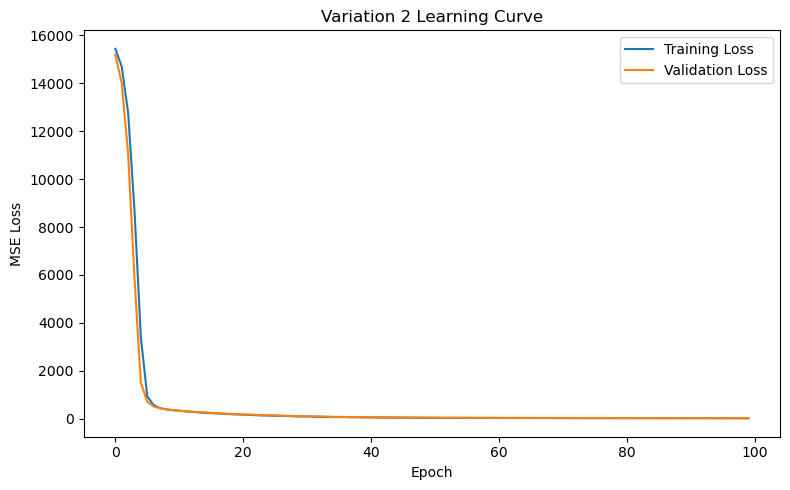

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_v2.history["loss"], label="Training Loss")
plt.plot(history_v2.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Variation 2 Learning Curve")
plt.legend()

plt.tight_layout()
plt.show()

### BUILDING ARCHITECHURE THREE AND THRID VARIATION

In [38]:
import importlib
import models

importlib.reload(models)

from models import build_tuned_model

In [39]:
model_v3 = build_tuned_model(
    X_train_scaled.shape[1]
)

model_v3.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history_v3 = model_v3.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 15653.8682 - mae: 124.9272 - val_loss: 15617.0322 - val_mae: 124.7921
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15549.6152 - mae: 124.5079 - val_loss: 15501.2861 - val_mae: 124.3264
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 15381.7012 - mae: 123.8291 - val_loss: 15247.4854 - val_mae: 123.2969
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 15014.2539 - mae: 122.3302 - val_loss: 14692.4014 - val_mae: 121.0114
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 14244.7188 - mae: 119.1261 - val_loss: 13605.5439 - val_mae: 116.3955
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 12845.3506 - mae: 113.0454 - val_loss: 11769.1406 - val_mae: 108.1141
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 10645.6650 - mae: 102.6963 - val_loss: 9115.1611 - val_mae: 94.7773
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7696.7769 - mae: 86.7624 - val_los

In [41]:
y_pred_v3 = model_v3.predict(X_test_scaled)

test_metrics_v3 = calculate_regression_metrics(
    y_test,
    y_pred_v3.flatten()
)

print_regression_metrics(test_metrics_v3)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
MAE:  4.2948
RMSE: 5.4331
R²:   0.4108


In [42]:
from analysis import create_model_comparison, calculate_baseline_changes


experiment_results = {
    "Baseline": test_metrics,
    "Variation 1 - Log Frequency": test_metrics_v1,
    "Variation 2 - Larger Network": test_metrics_v2,
    "Variation 3 - Lower Learning Rate": test_metrics_v3
}


comparison_df = create_model_comparison(
    experiment_results
)


comparison_df = calculate_baseline_changes(
    comparison_df
)


comparison_df

,Model,MAE,RMSE,R2,MAE_change_pct,RMSE_change_pct,R2_change_pct
0,Baseline,4.120574,5.210536,0.458075,0.000000,0.000000,0.000000
1,Variation 1 - Log Frequency,4.843306,6.105693,0.255877,17.539599,17.179746,-44.140683
2,Variation 2 - Larger Network,3.326798,4.303642,0.630302,-19.263721,-17.404996,37.598091
3,Variation 3 - Lower Learning Rate,4.294821,5.433085,0.410793,4.228705,4.271145,-10.321772


In [43]:
from pathlib import Path


tables_dir = Path("../outputs/tables")
tables_dir.mkdir(parents=True, exist_ok=True)


comparison_df.to_csv(
    tables_dir / "model_comparison.csv",
    index=False
)


comparison_df.round(4).to_csv(
    tables_dir / "model_comparison_rounded.csv",
    index=False
)


comparison_df.round(4)

,Model,MAE,RMSE,R2,MAE_change_pct,RMSE_change_pct,R2_change_pct
0,Baseline,4.1206,5.2105,0.4581,0.0000,0.0000,0.0000
1,Variation 1 - Log Frequency,4.8433,6.1057,0.2559,17.5396,17.1797,-44.1407
2,Variation 2 - Larger Network,3.3268,4.3036,0.6303,-19.2637,-17.4050,37.5981
3,Variation 3 - Lower Learning Rate,4.2948,5.4331,0.4108,4.2287,4.2711,-10.3218


In [44]:
comparison_df.round(4).to_excel(
    tables_dir / "model_comparison.xlsx",
    index=False
)

print("Saved:", tables_dir / "model_comparison.xlsx")

Saved: ..\outputs\tables\model_comparison.xlsx


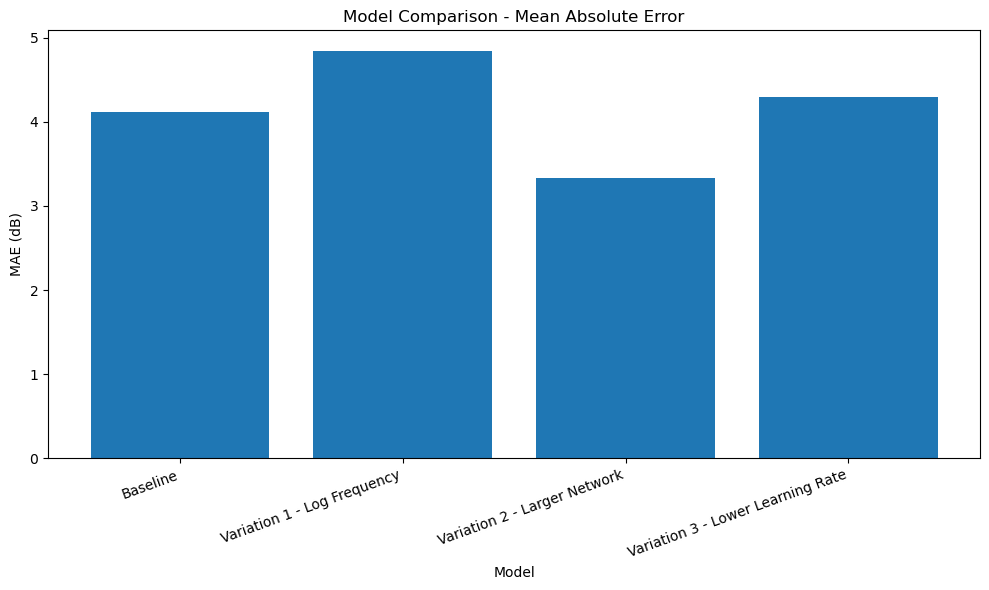

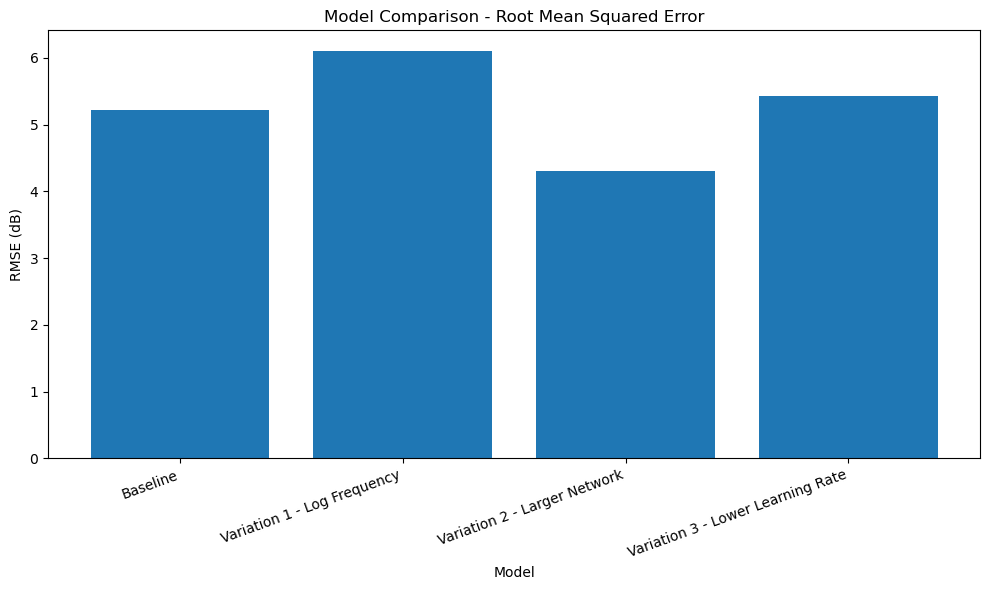

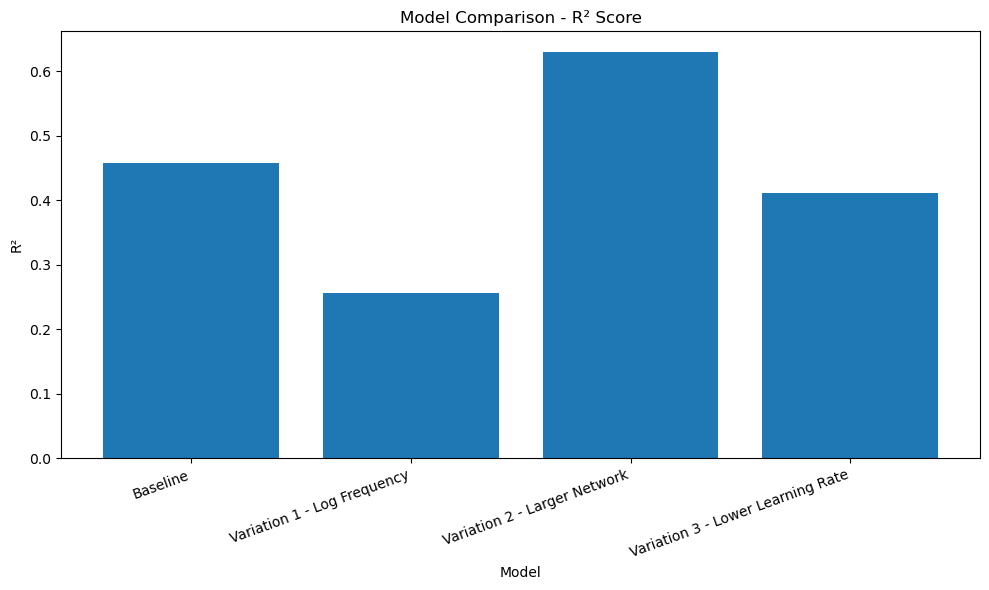

Model comparison figures saved to:
..\outputs\figures


In [45]:
from pathlib import Path
import matplotlib.pyplot as plt


figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)


metrics_to_plot = [
    ("MAE", "MAE (dB)", "Model Comparison - Mean Absolute Error",
     "model_comparison_mae.png"),
    ("RMSE", "RMSE (dB)", "Model Comparison - Root Mean Squared Error",
     "model_comparison_rmse.png"),
    ("R2", "R²", "Model Comparison - R² Score",
     "model_comparison_r2.png")
]


for metric, ylabel, title, filename in metrics_to_plot:

    plt.figure(figsize=(10, 6))

    plt.bar(
        comparison_df["Model"],
        comparison_df[metric]
    )

    plt.xlabel("Model")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.xticks(
        rotation=20,
        ha="right"
    )

    plt.tight_layout()

    plt.savefig(
        figures_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


print("Model comparison figures saved to:")
print(figures_dir)

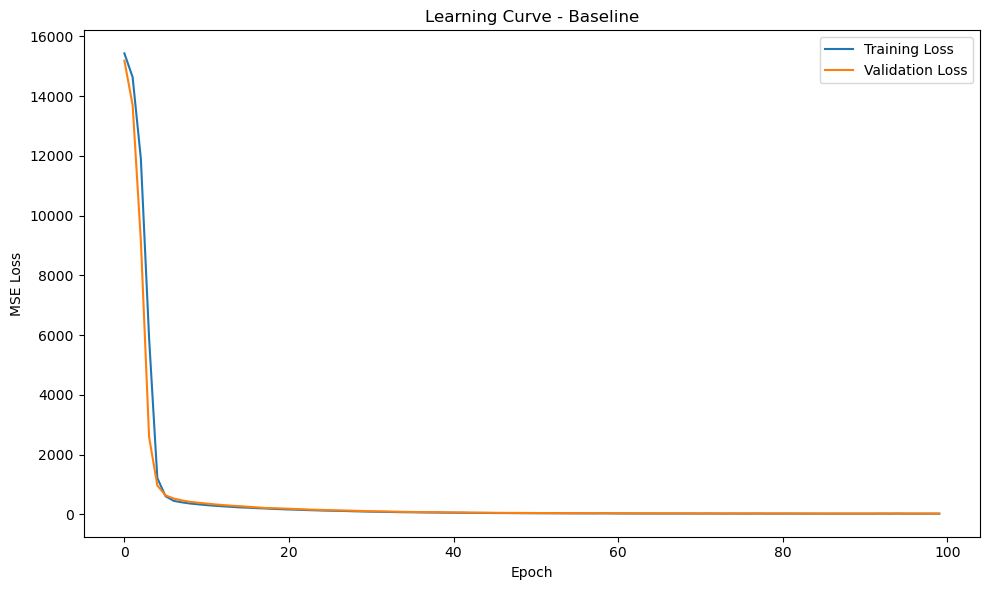

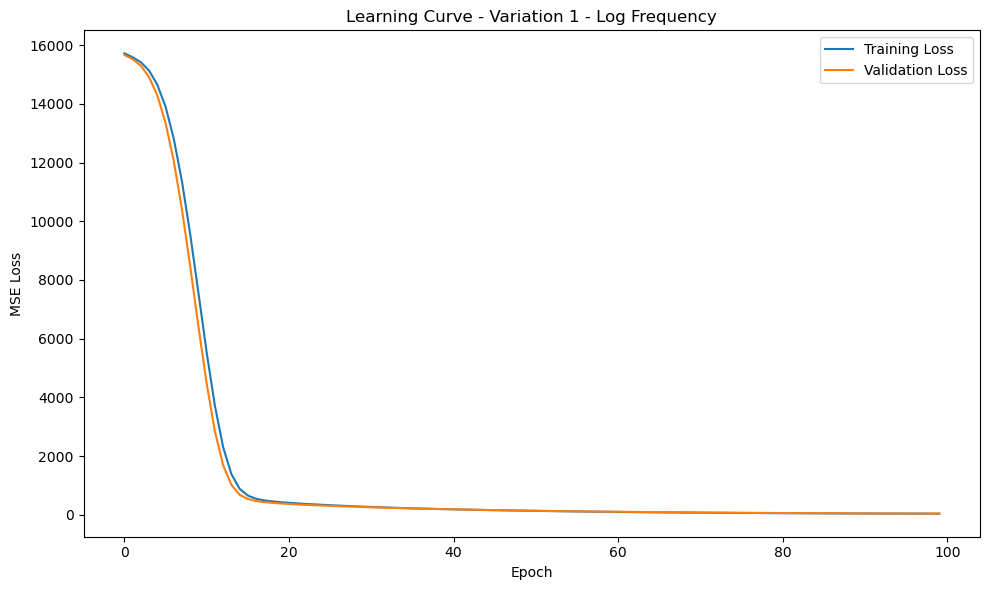

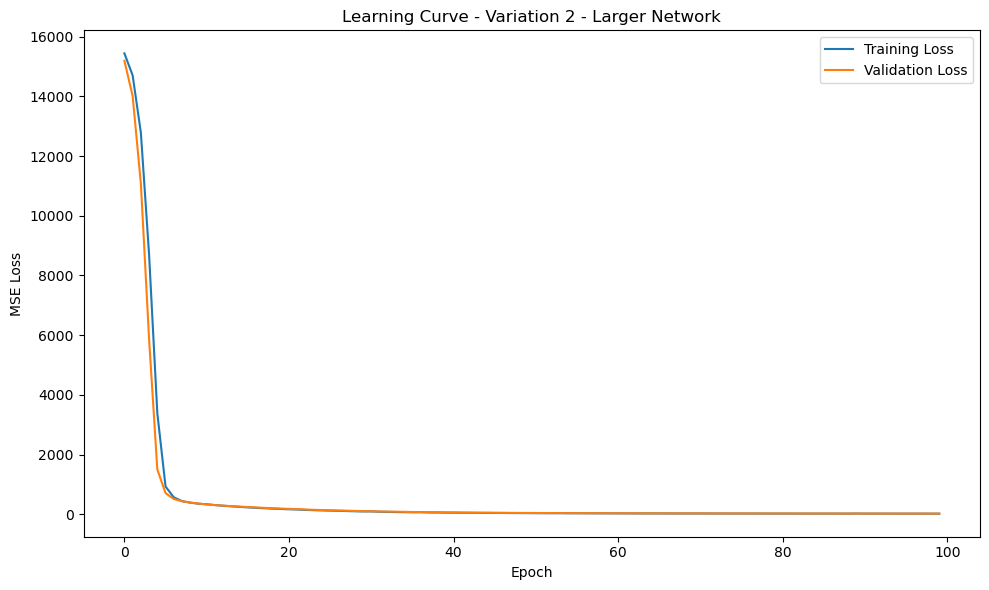

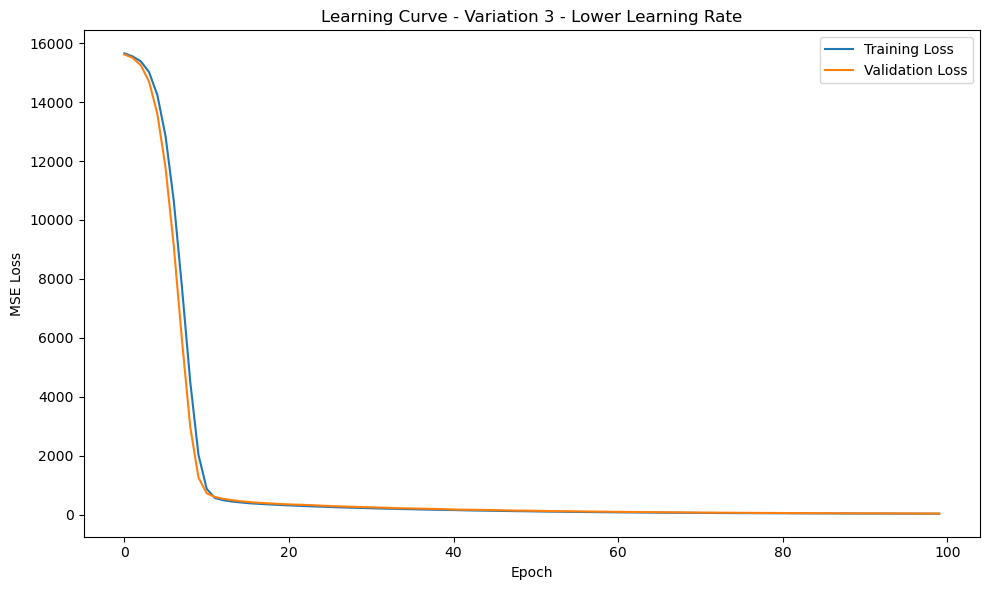

Learning curves saved to:
..\outputs\figures


In [46]:
histories = {
    "Baseline": history,
    "Variation 1 - Log Frequency": history_v1,
    "Variation 2 - Larger Network": history_v2,
    "Variation 3 - Lower Learning Rate": history_v3
}


for model_name, model_history in histories.items():

    plt.figure(figsize=(10, 6))

    plt.plot(
        model_history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        model_history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title(f"Learning Curve - {model_name}")

    plt.legend()

    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "")
        + "_learning_curve.png"
    )

    plt.savefig(
        figures_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


print("Learning curves saved to:")
print(figures_dir)

In [48]:
from analysis import (
    plot_actual_vs_predicted,
    plot_residuals
)

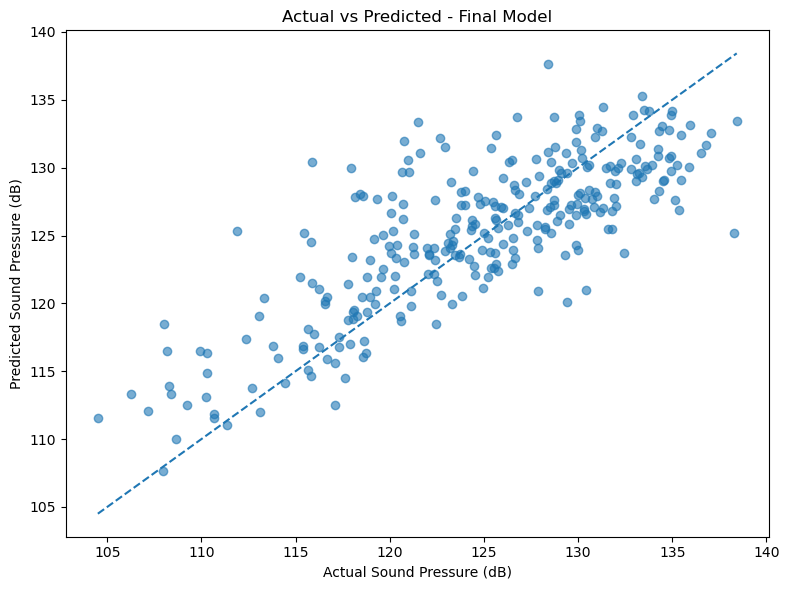

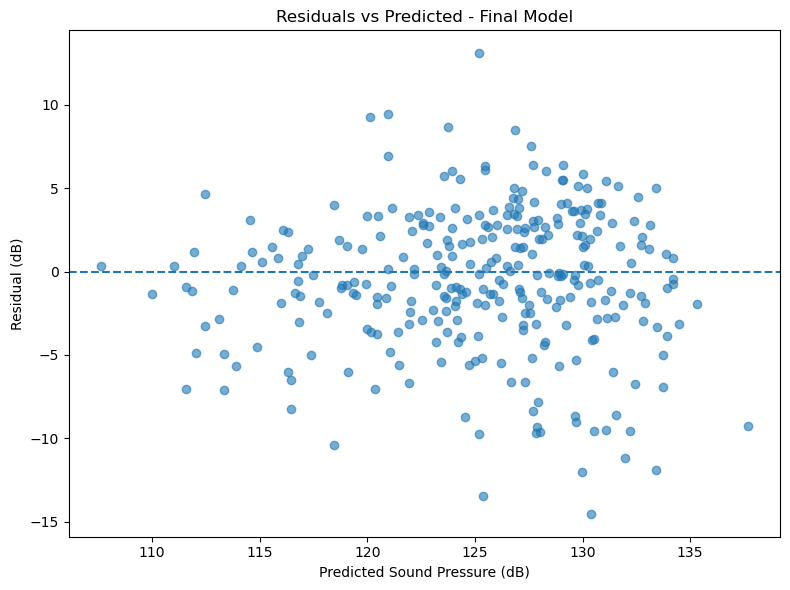

Final-model diagnostic figures saved.


In [49]:
import numpy as np


# Generate predictions from the selected final model
y_pred_final = model_v2.predict(
    X_test_scaled,
    verbose=0
).flatten()


# Actual vs Predicted
plot_actual_vs_predicted(
    y_test.to_numpy(),
    y_pred_final,
    "Actual vs Predicted - Final Model"
)

plt.savefig(
    figures_dir / "actual_vs_predicted_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Residuals
plot_residuals(
    y_test.to_numpy(),
    y_pred_final,
    "Residuals vs Predicted - Final Model"
)

plt.savefig(
    figures_dir / "residuals_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


print("Final-model diagnostic figures saved.")

In [50]:
from pathlib import Path
import pandas as pd


processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)


# Save the original train/test splits
train_data = X_train.copy()
train_data["scaled_sound_pressure_db"] = y_train.values

test_data = X_test.copy()
test_data["scaled_sound_pressure_db"] = y_test.values


train_data.to_csv(
    processed_dir / "airfoil_train.csv",
    index=False
)

test_data.to_csv(
    processed_dir / "airfoil_test.csv",
    index=False
)


# Save the complete processed dataset
processed_data = df[
    FEATURE_COLUMNS + [TARGET_COLUMN]
].copy()

processed_data.to_csv(
    processed_dir / "airfoil_processed.csv",
    index=False
)


print("Processed datasets saved:")
print(processed_dir / "airfoil_train.csv")
print(processed_dir / "airfoil_test.csv")
print(processed_dir / "airfoil_processed.csv")

print("\nShapes:")
print("Training:", train_data.shape)
print("Testing:", test_data.shape)
print("Complete:", processed_data.shape)

Processed datasets saved:
..\data\processed\airfoil_train.csv
..\data\processed\airfoil_test.csv
..\data\processed\airfoil_processed.csv

Shapes:
Training: (1202, 6)
Testing: (301, 6)
Complete: (1503, 6)


In [51]:
from pathlib import Path


project_root = Path("..")

output_dirs = [
    project_root / "data" / "processed",
    project_root / "outputs" / "figures",
    project_root / "outputs" / "tables"
]


for directory in output_dirs:
    print(f"\n{directory}:")
    
    for file in sorted(directory.iterdir()):
        if file.is_file():
            print(f"  ✓ {file.name}")


..\data\processed:
  ✓ airfoil_processed.csv
  ✓ airfoil_test.csv
  ✓ airfoil_train.csv

..\outputs\figures:
  ✓ actual_vs_predicted_final.png
  ✓ baseline_learning_curve.png
  ✓ model_comparison_mae.png
  ✓ model_comparison_r2.png
  ✓ model_comparison_rmse.png
  ✓ residuals_final.png
  ✓ variation_1__log_frequency_learning_curve.png
  ✓ variation_2__larger_network_learning_curve.png
  ✓ variation_3__lower_learning_rate_learning_curve.png

..\outputs\tables:
  ✓ model_comparison.csv
  ✓ model_comparison.xlsx
  ✓ model_comparison_rounded.csv


In [52]:
import numpy as np
import pandas as pd


histories = {
    "Baseline": history,
    "Variation 1 - Log Frequency": history_v1,
    "Variation 2 - Larger Network": history_v2,
    "Variation 3 - Lower Learning Rate": history_v3
}


diagnostic_rows = []


for model_name, model_history in histories.items():

    validation_loss = np.array(
        model_history.history["val_loss"]
    )

    validation_mae = np.array(
        model_history.history["val_mae"]
    )

    best_loss_epoch = np.argmin(validation_loss) + 1
    best_mae_epoch = np.argmin(validation_mae) + 1

    diagnostic_rows.append({
        "Model": model_name,
        "Epochs": len(validation_loss),
        "Best_Validation_Loss": validation_loss.min(),
        "Best_Validation_Loss_Epoch": best_loss_epoch,
        "Best_Validation_MAE": validation_mae.min(),
        "Best_Validation_MAE_Epoch": best_mae_epoch
    })


diagnostic_df = pd.DataFrame(
    diagnostic_rows
)


# Residual statistics for the final model
residuals_final = (
    y_test.to_numpy() - y_pred_final
)


residual_summary = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Standard Deviation",
        "Minimum",
        "Maximum",
        "Mean Absolute Residual"
    ],
    "Value": [
        residuals_final.mean(),
        residuals_final.std(),
        residuals_final.min(),
        residuals_final.max(),
        np.abs(residuals_final).mean()
    ]
})


print("MODEL LEARNING DIAGNOSTICS")
display(diagnostic_df.round(4))

print("\nFINAL MODEL RESIDUAL DIAGNOSTICS")
display(residual_summary.round(4))

MODEL LEARNING DIAGNOSTICS


,Model,Epochs,Best_Validation_Loss,Best_Validation_Loss_Epoch,Best_Validation_MAE,Best_Validation_MAE_Epoch
0,Baseline,100,22.5902,100,3.6636,100
1,Variation 1 - Log Frequency,100,41.6569,100,4.9184,100
2,Variation 2 - Larger Network,100,21.9345,99,3.7280,99
3,Variation 3 - Lower Learning Rate,100,35.0535,100,4.5570,100



FINAL MODEL RESIDUAL DIAGNOSTICS


,Statistic,Value
0,Mean,-0.5300
1,Standard Deviation,4.2709
2,Minimum,-14.5305
3,Maximum,13.0947
4,Mean Absolute Residual,3.3268


In [53]:
diagnostic_tables_dir = Path("../outputs/tables")
diagnostic_tables_dir.mkdir(parents=True, exist_ok=True)


diagnostic_df.round(4).to_csv(
    diagnostic_tables_dir / "model_learning_diagnostics.csv",
    index=False
)


residual_summary.round(4).to_csv(
    diagnostic_tables_dir / "final_model_residual_diagnostics.csv",
    index=False
)


diagnostic_df.round(4).to_excel(
    diagnostic_tables_dir / "model_learning_diagnostics.xlsx",
    index=False
)


residual_summary.round(4).to_excel(
    diagnostic_tables_dir / "final_model_residual_diagnostics.xlsx",
    index=False
)


print("Diagnostic tables saved successfully.")

Diagnostic tables saved successfully.


In [54]:
from pathlib import Path


models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)


model.save(
    models_dir / "baseline_model.keras"
)

model_v1.save(
    models_dir / "variation_1_log_frequency.keras"
)

model_v2.save(
    models_dir / "variation_2_larger_network.keras"
)

model_v3.save(
    models_dir / "variation_3_lower_learning_rate.keras"
)


print("Trained models saved successfully:")
print("✓ baseline_model.keras")
print("✓ variation_1_log_frequency.keras")
print("✓ variation_2_larger_network.keras")
print("✓ variation_3_lower_learning_rate.keras")

Trained models saved successfully:
✓ baseline_model.keras
✓ variation_1_log_frequency.keras
✓ variation_2_larger_network.keras
✓ variation_3_lower_learning_rate.keras
